<a href="https://colab.research.google.com/github/andreacangiani/NSPDE-ANA2024/blob/main/Python/CP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Divided differences using sparse matrix

Import the usual modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym

New module: sparse algebra

In [2]:
import scipy.sparse as sp

Function implementing the forward difference in sparse format

In [3]:

def func(N):
    data=[-np.ones(N+1),np.ones(N)]
    return sp.diags(data,[0,1],format="csr")

print(func(4))
A=func(4)
print(A.todense())

  (0, 0)	-1.0
  (0, 1)	1.0
  (1, 1)	-1.0
  (1, 2)	1.0
  (2, 2)	-1.0
  (2, 3)	1.0
  (3, 3)	-1.0
  (3, 4)	1.0
  (4, 4)	-1.0
[[-1.  1.  0.  0.  0.]
 [ 0. -1.  1.  0.  0.]
 [ 0.  0. -1.  1.  0.]
 [ 0.  0.  0. -1.  1.]
 [ 0.  0.  0.  0. -1.]]


Exmaple of Forward Difference matrix to approximate the derivative of the solution and then at the points on an interval and then computing the error:

In [4]:
t = sym.var('t')
fsym=sym.sin(t)
fdsym=fsym.diff(t,1)
f=sym.lambdify(t,fsym)
fd=sym.lambdify(t,fdsym)

a=0
b=np.pi/2
N=100
h=(b-a)/N
A=func(N)/h
x=np.linspace(a,b,N+1)
u=f(x)
uhD=A.dot(u)
#print(uhD)
print(max(abs(uhD[1:N]-fd(x[1:N]))))

0.007853497167543824


Example: Use central divided difference for the above example

Test: use the FD to evaluate the derivative of $f(x)=\frac{x^2}{2}$

In [5]:
import numpy as np
import sympy as sym
# Fix function f using symbolic tool
t = sym.var('t')
fsym = 0.5 * t**2
fdsym=fsym.diff(t,1)
# Define the function as an inline function
f = sym.lambdify(t, fsym )
fd = sym.lambdify(t,fdsym )


def forward_diff(n):
    data=[-np.ones(n+1),np.ones(n)]
    return sp.diags(data,[0,1],format="csr")

# Set up interval and cardinality of the grid

# set up grid points


# Evaluate FD matrix


# Values of the derivative at the grid points


# Print results


Compute max error

In [6]:
a=0
b=1
n=1000
h=1/n
x=np.linspace(a,b,n+1)
A=forward_diff(n)/h
u=f(x)
uhd=A.dot(u)
#print(uhd)
print(max(abs(uhd[0:n]-fd(x[0:n]))))

0.0005000000000854321


Exercise 1. Find a way to evaluate execution time and compare full vs sparse exectution time in function of the grid size N.

Repeat the above exersise and use central divided difference instead of forward divided difference

# Finite Differences for two-points boundary value problems with constant coefficients

Poisson problem in 1D:

$-u''(x)=f(x) \quad \in (a,b)$

$u(a)=0, \quad u(b)=0$

We use the second central divided difference to approxima the second derivative.

Given $h>0$,

$u''(x)≈\frac{u(x+h)-2u(x)+u(x-h)}{h^2}$

Function for second central matrix

In [7]:
import numpy as np
import scipy.sparse as sp
import sympy as sym

In [8]:
def diff_U(N):
    data=[np.ones(N),-2*np.ones(N+1),np.ones(N)]
    A=sp.diags(data,[-1,0,1],format='csr')
    return A

Example of second central matrix.

In [9]:
A=diff_U(4)
print(diff_U(4))
print(A.todense())

  (0, 0)	-2.0
  (0, 1)	1.0
  (1, 0)	1.0
  (1, 1)	-2.0
  (1, 2)	1.0
  (2, 1)	1.0
  (2, 2)	-2.0
  (2, 3)	1.0
  (3, 2)	1.0
  (3, 3)	-2.0
  (3, 4)	1.0
  (4, 3)	1.0
  (4, 4)	-2.0
[[-2.  1.  0.  0.  0.]
 [ 1. -2.  1.  0.  0.]
 [ 0.  1. -2.  1.  0.]
 [ 0.  0.  1. -2.  1.]
 [ 0.  0.  0.  1. -2.]]


Test problem:

$(a,b)=(0,\pi)$

u(x)=sin(x)

In [10]:
t=sym.var('t')
fsym=sym.sin(t)
f=sym.lambdify(t,fsym)
fddsym=fsym.diff(t,2)
fdd=sym.lambdify(t,fddsym)
a=0
b=np.pi

Define FD problem:

for $h=(b-a)/N$

$ A U = - h^2 F $

with $A$ the nominator of CD formula.

In [11]:
N=50
h=(b-a)/N
x=np.linspace(a,b,N+1)
A=(1/(h**2))*diff_U(N)
F=fdd(x)
uh=np.zeros(N+1)
A=A[1:-1,1:-1]
F=F[1:-1]

Import solver

In [12]:
from scipy.sparse.linalg import spsolve

Solve problem and print result

In [13]:
uh=spsolve(A,F)
print(uh)

[0.06281118 0.12537447 0.18744297 0.24877172 0.30911868 0.36824568
 0.42591939 0.4819122  0.53600311 0.58797866 0.63763374 0.68477236
 0.7292085  0.77076678 0.8092832  0.84460575 0.87659503 0.90512479
 0.93008243 0.95136946 0.96890188 0.98261047 0.99244116 0.99835513
 1.00032905 0.99835513 0.99244116 0.98261047 0.96890188 0.95136946
 0.93008243 0.90512479 0.87659503 0.84460575 0.8092832  0.77076678
 0.7292085  0.68477236 0.63763374 0.58797866 0.53600311 0.4819122
 0.42591939 0.36824568 0.30911868 0.24877172 0.18744297 0.12537447
 0.06281118]


**Exercise 2.** test for convergence and plot convergence plot

In [14]:
noexp=10
error=np.zeros(noexp)
NN=np.zeros(noexp)
for i in range(noexp):
    N=2**(i+1)
    h=(b-a)/N
    x=np.linspace(a,b,N+1)
    A=(1/(h**2))*diff_U(N)
    F=fdd(x)
    u=f(x)
    A=A[1:-1,1:-1]
    F=F[1:-1]
    uh=spsolve(A,F)
    error[i]=max(abs(uh-u[1:-1]))
    NN[i]=N
    
    
print(error)

[2.33700550e-01 5.30292875e-02 1.29507467e-02 3.21896444e-03
 8.03577679e-04 2.00821810e-04 5.02009159e-05 1.25499454e-05
 3.13746853e-06 7.84365696e-07]


Compute the order of convergence

In [15]:
np.log(error[0:noexp-1]/error[1:noexp])/np.log(2)

array([2.13979986, 2.03375408, 2.00836674, 2.00208724, 2.00052153,
       2.00013037, 2.00003259, 2.0000082 , 2.00000264])

Plot order of convergence

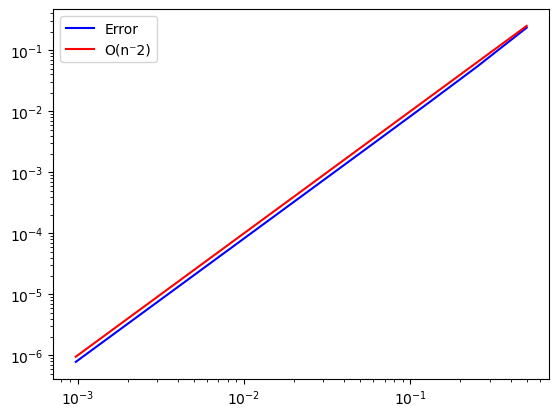

In [16]:
import matplotlib.pyplot as plt

plt.loglog(1/NN, error, color='blue', label='Error')
plt.loglog(1/NN, 1/(NN**2), color='red', label='O(n⁻2)')

plt.legend()
plt.show()

**Exercise 3.** Solve the problem with nonhomogeneous Dirichlet conditions:

$-\alpha u''(x)=f(x) \quad \in (a,b)$

$u(a)=u_a, \quad u(b)=u_b$

For example, you could fix: $(a,b)=(0,\pi/2)$, solution $u$ as before, $\alpha=\frac{1}{2}$

**Exercise 4.** Solve the problem with (homogeneous) Neumann conditions:

$-\alpha u''(x)=f(x) \quad \in (a,b)$

$u(a)=u_a, \quad u'(b)=0$

For example, you could fix: $(a,b)=(0,\pi/2)$, solution $u$ as before, $\alpha=1$.

**Exercise 5.** Solve the reaction-advection-diffusion problem (still with central differences):

$-\alpha u''(x)+\beta u'(x)+\gamma u(x)=f(x) \quad \in (a,b)$

$u(a)=u_a, \quad u(b)=u_b$
